# Model Comparison and Final Pick

Three candidates, evaluated on identical footing:

| | notebook |
|---|---|
| Random forest, 500 trees | `thyroid.ipynb` |
| Decision tree, depth 3 | `decision_tree.ipynb` |
| SVM, RBF kernel, C=10 | `svm.ipynb` |

**Two methodological commitments.**

*Repeated cross-validation, not a single split.* The held-out test set has 58 hypothyroid patients,
so one patient is 1.7% of recall and single-split differences under a couple of points are noise.
Everything below uses 5-fold CV repeated 5 times — 25 fits per model — reported as mean ± standard
deviation, so a gap can be judged against its own variability.

*Recall and precision on the minority class, never accuracy.* At 7.7% prevalence, predicting
"negative" for everyone scores 92.3%. Accuracy cannot distinguish these models and is not reported.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import precision_recall_curve

warnings.filterwarnings("ignore")
RF_C, DT_C, SVM_C = "#2a78d6", "#eb6834", "#1baf7a"

## Data

In [2]:
df = pd.read_csv("../dataset/cleaned_dataset_Thyroid1.csv").drop_duplicates()

for flag, value in [("TSH measured", "TSH"), ("TT4 measured", "TT4"),
                    ("T4U measured", "T4U"), ("FTI measured", "FTI")]:
    df.loc[df[flag] == 0, value] = np.nan
df.loc[~df["sex"].isin([0.0, 1.0]), "sex"] = np.nan
df = df.drop(columns=["hypopituitary"])

X = df.drop(columns=["binaryClass"])
y = df["binaryClass"]
print(f"{len(df)} patients, {int(y.sum())} hypothyroid ({100*y.mean():.1f}%)")

3708 patients, 291 hypothyroid (7.8%)


### The three contenders

The SVM carries its preprocessing inside a pipeline: `log1p(TSH)`, median imputation, and scaling.
All three are needed — it cannot take `NaN`, its kernel is distance-based so it needs scaling, and
the log transform was worth more to it than any hyperparameter (0.84 → 0.97 average precision in
`svm.ipynb`). Putting them in the pipeline keeps every fold leak-free.

The tree models need none of that: they split on rank, so scale is irrelevant, and scikit-learn
lets them read `NaN` as information rather than filling it.

In [3]:
log_tsh = ColumnTransformer([("log", FunctionTransformer(np.log1p), ["TSH"])],
                            remainder="passthrough")

MODELS = {
    "Random forest": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=2, class_weight="balanced",
        random_state=42, n_jobs=-1),
    "Decision tree (d3)": DecisionTreeClassifier(
        max_depth=3, class_weight="balanced", random_state=42),
    "SVM (RBF, C=10)": make_pipeline(
        log_tsh, SimpleImputer(strategy="median"), StandardScaler(),
        CalibratedClassifierCV(SVC(C=10, class_weight="balanced", random_state=42),
                               ensemble=False)),
}
COLOURS = dict(zip(MODELS, [RF_C, DT_C, SVM_C]))

## 1. Repeated cross-validation (25 fits per model)

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
raw = {}
rows = []
for name, model in MODELS.items():
    r = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                       scoring=["average_precision", "recall", "precision"])
    raw[name] = r
    rows.append({
        "model": name,
        "avg_precision": f"{r['test_average_precision'].mean():.4f} ± {r['test_average_precision'].std():.4f}",
        "recall": f"{r['test_recall'].mean():.4f} ± {r['test_recall'].std():.4f}",
        "precision": f"{r['test_precision'].mean():.4f} ± {r['test_precision'].std():.4f}",
        "fit_time_s": f"{r['fit_time'].mean():.3f}",
    })
pd.DataFrame(rows).set_index("model")

,avg_precision,recall,precision,fit_time_s
model,,,,
Random forest,0.9885 ± 0.0118,0.9931 ± 0.0108,0.9089 ± 0.0345,0.850
Decision tree (d3),0.9452 ± 0.0303,0.9931 ± 0.0108,0.9166 ± 0.0509,0.003
"SVM (RBF, C=10)",0.9460 ± 0.0181,0.8406 ± 0.0577,0.9248 ± 0.0367,0.124


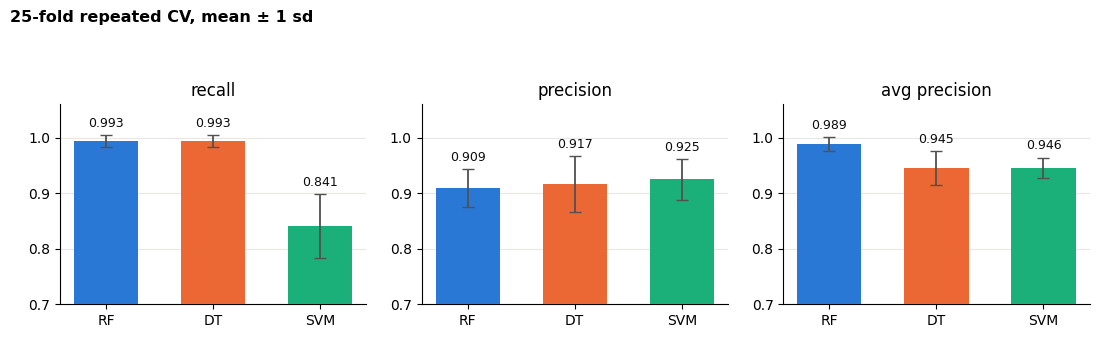

In [5]:
metrics = [("test_recall", "recall"), ("test_precision", "precision"),
           ("test_average_precision", "avg precision")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (key, title) in zip(axes, metrics):
    names = list(MODELS)
    means = [raw[n][key].mean() for n in names]
    stds = [raw[n][key].std() for n in names]
    ax.bar(range(3), means, yerr=stds, color=[COLOURS[n] for n in names], width=0.6,
           error_kw=dict(ecolor="#52514e", lw=1.3, capsize=4), zorder=3)
    for i, (m, s) in enumerate(zip(means, stds)):
        ax.text(i, m + s + 0.015, f"{m:.3f}", ha="center", fontsize=9, color="#0b0b0b")
    ax.set_xticks(range(3), ["RF", "DT", "SVM"])
    ax.set_ylim(0.7, 1.06)
    ax.set_title(title)
    ax.grid(axis="y", color="#e8e7e3", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("25-fold repeated CV, mean ± 1 sd", x=0.005, ha="left", fontsize=11.5,
             fontweight="semibold")
plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

**Read the recall panel first — it is the one that decides this.**

- The random forest and the decision tree are **indistinguishable on recall**: 0.9931 ± 0.0108
  each, to four decimal places. They catch the same patients.
- The **SVM is 15 points behind on recall** (0.8406 ± 0.0577), a gap far larger than either
  standard deviation. It also has the widest spread, so it is the least stable.
- Precision is a three-way tie once the deviations are taken into account (0.909–0.925, with sds
  of 0.035–0.051).
- On average precision the forest leads clearly (0.9885 vs 0.945 and 0.946). The tree and the SVM
  are tied there — a 0.0008 difference against sds of 0.018–0.030 is nothing.

So the SVM is eliminated: it misses substantially more patients for no gain in precision. The
decision now rests on why the forest's average precision is so much better when its recall and
precision are not.

## 2. Why average precision disagrees with the operating point

Average precision integrates over every possible threshold. A depth-3 tree has eight leaves, so it
can only ever emit a handful of distinct scores — it cannot rank patients finely, and the metric
penalises that even when its chosen cut is excellent.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
positives = int((y_test == 1).sum())

fitted, scores = {}, {}
for name, model in MODELS.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    scores[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:20s} distinct predicted scores: {len(np.unique(scores[name])):4d}")

Random forest        distinct predicted scores:  731
Decision tree (d3)   distinct predicted scores:    4
SVM (RBF, C=10)      distinct predicted scores:  742


Four distinct scores against 731 and 742. That is the whole explanation for the average-precision
gap, and it means the metric is measuring *threshold flexibility*, not correctness.

The fair comparison is therefore at a **matched operating point**. Below, each model is given the
lowest threshold that reaches at least 95% recall — a plausible requirement for a screening test —
and judged on what that costs in false alarms.

In [7]:
rows = []
for name, s in scores.items():
    for t in np.unique(np.r_[s, 1.0])[::-1]:
        recall = ((s >= t) & (y_test == 1)).sum() / positives
        if recall >= 0.95:
            rows.append({"model": name, "threshold": round(t, 3), "recall": round(recall, 4),
                         "missed": int(((s < t) & (y_test == 1)).sum()),
                         "false_alarms": int(((s >= t) & (y_test == 0)).sum())})
            break
pd.DataFrame(rows).set_index("model")

,threshold,recall,missed,false_alarms
model,,,,
Random forest,0.709,0.9655,2,1
Decision tree (d3),0.995,1.0000,0,1
"SVM (RBF, C=10)",0.177,0.9655,2,19


At a matched operating point the ordering inverts. The **decision tree reaches 100% recall with a
single false alarm** — it misses nobody. The forest needs to give up two patients to get down to
one false alarm. The SVM needs **19 false alarms** to reach the same recall, which is the same
elimination verdict stated a second way.

So the forest's average-precision lead does not translate into a better operating point on this
test set. What it buys is the ability to *choose* one.

## 3. Cost view

Screening is asymmetric: a missed hypothyroid patient is worse than a false alarm that a
confirmatory test clears. Sweeping that ratio shows whether the ranking is stable or an artifact of
one particular trade-off.

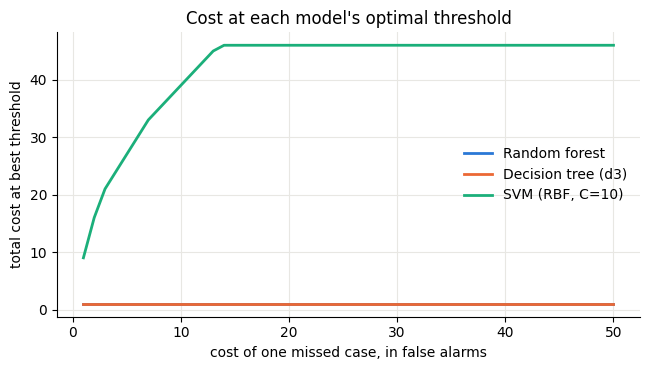

In [8]:
ratios = np.arange(1, 51)
fig, ax = plt.subplots(figsize=(6.6, 3.8))
for name, s in scores.items():
    best = []
    for ratio in ratios:
        costs = [((s < t) & (y_test == 1)).sum() * ratio + ((s >= t) & (y_test == 0)).sum()
                 for t in np.unique(np.r_[s, 1.0])]
        best.append(min(costs))
    ax.plot(ratios, best, color=COLOURS[name], label=name, linewidth=2)
ax.set_xlabel("cost of one missed case, in false alarms")
ax.set_ylabel("total cost at best threshold")
ax.set_title("Cost at each model's optimal threshold")
ax.legend(frameon=False)
ax.grid(color="#e8e7e3")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The forest and the tree track each other closely across the whole range, while the SVM is worse
everywhere and separates further as missed cases get more expensive. No crossover changes the
verdict.

## 4. Criteria that are not performance

In [9]:
pd.DataFrame([
    {"criterion": "recall (25-fold CV)", "Random forest": "0.9931", "Decision tree": "0.9931",
     "SVM": "0.8406"},
    {"criterion": "distinct scores (threshold tuning)", "Random forest": "731",
     "Decision tree": "4", "SVM": "742"},
    {"criterion": "mean fit time", **{k: f"{raw[n]['fit_time'].mean():.3f} s"
     for k, n in zip(["Random forest", "Decision tree", "SVM"], MODELS)}},
    {"criterion": "needs scaling / imputation", "Random forest": "no", "Decision tree": "no",
     "SVM": "yes, both"},
    {"criterion": "uses missingness as signal", "Random forest": "yes", "Decision tree": "yes",
     "SVM": "no — imputed to median"},
    {"criterion": "auditable by a clinician", "Random forest": "no — 500 trees",
     "Decision tree": "yes — 8 leaves", "SVM": "no — kernel"},
]).set_index("criterion")

,Random forest,Decision tree,SVM
criterion,,,
recall (25-fold CV),0.9931,0.9931,0.8406
distinct scores (threshold tuning),731,4,742
mean fit time,0.850 s,0.003 s,0.124 s
needs scaling / imputation,no,no,"yes, both"
uses missingness as signal,yes,yes,no — imputed to median
auditable by a clinician,no — 500 trees,yes — 8 leaves,no — kernel


One row deserves emphasis. The SVM imputes 307 unmeasured TSH values to the median, which asserts
a normal TSH for patients nobody tested. The tree models read that absence as information. Given
how central TSH is to this label, that is a real modelling difference and not a technicality.

## 5. Final pick

**Primary model: the random forest. Shipped alongside it: the depth-3 decision tree.**

*Why the forest.* It matches the tree on every decision metric and beats it decisively on average
precision (0.9885 ± 0.0118 vs 0.9452 ± 0.0303). That lead is specifically threshold flexibility:
731 distinct scores against 4. If prevalence changes, or the cost of a missed case is revised, or
the model is deployed to a population with a different base rate, the forest can be retuned to a
new precision/recall point. The tree has four cuts available and nothing in between — at a fixed
operating point that costs nothing, but it cannot be moved.

*Why the tree ships too.* It is not a consolation prize. It equals the forest's recall in CV to
four decimals, beats it at the matched operating point (0 missed vs 2), fits in milliseconds, and can be
read in full:

```
TSH <= 6.05 → mostly negative, unless TT4 is very low
TSH >  6.05 → hypothyroid, unless already on thyroxine (then judge on FTI)
```

For a clinical setting that auditability is worth more than 0.04 of average precision. It is also
the best possible sanity check on the forest: when a 500-tree ensemble and eight readable leaves
agree, the result is unlikely to be an artifact.

*Why not the SVM.* Eliminated on the metric that matters. Recall 0.8406 ± 0.0577 against 0.9931
for both tree models — roughly 16% of hypothyroid patients missed instead of under 1% — with no
compensating precision gain, the widest fold-to-fold spread of the three, the most preprocessing,
and the only model that discards the missingness signal.

### Caveats that travel with this pick

These apply to all three models and were established in `thyroid.ipynb`:

- **The label is close to a deterministic rule on TSH.** Only 2 of 291 hypothyroid cases sit below
  TSH 6.05. The source diagnoses were assigned by clinicians applying that rule to these same
  columns, so every model here is partly recovering its own label definition. Strip TSH and the
  forest falls from 0.996 to 0.360 average precision.
- **The population is already referred, not screened.** `on thyroxine` is the second strongest
  feature and is circular — being on replacement means someone already diagnosed it. Expect lower
  performance on an unscreened population where TSH is often not ordered.
- **This is binary, negative vs hypothyroid.** The brief's hyperthyroid class is not in this
  dataset and cannot be recovered from it.